In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

print("Python:", sys.version.split()[0])
print("Путь:", sys.executable)
print("Готовы анализировать Formula 1!")

Python: 3.12.10
Путь: c:\Users\Aisha\f1-race-analysis\.venv\Scripts\python.exe
Готовы анализировать Formula 1!


In [2]:
response = requests.get(
    "https://api.openf1.org/v1/sessions",
    params={"year": 2024, "session_name": "Race"},
    timeout=30,
)
response.raise_for_status()

races = pd.DataFrame(response.json())

races[[
    "session_key",
    "country_name",
    "circuit_short_name",
    "date_start",
]].sort_values("date_start")

,session_key,country_name,circuit_short_name,date_start
0,9472,Bahrain,Sakhir,2024-03-02T15:00:00+00:00
1,9480,Saudi Arabia,Jeddah,2024-03-09T17:00:00+00:00
2,9488,Australia,Melbourne,2024-03-24T04:00:00+00:00
3,9496,Japan,Suzuka,2024-04-07T05:00:00+00:00
4,9673,China,Shanghai,2024-04-21T07:00:00+00:00
5,9507,United States,Miami,2024-05-05T20:00:00+00:00
6,9515,Italy,Imola,2024-05-19T13:00:00+00:00
7,9523,Monaco,Monte Carlo,2024-05-26T13:00:00+00:00
8,9531,Canada,Montreal,2024-06-09T18:00:00+00:00
9,9539,Spain,Catalunya,2024-06-23T13:00:00+00:00


In [3]:
session_key = 9590

response = requests.get(
    "https://api.openf1.org/v1/drivers",
    params={"session_key": session_key},
    timeout=30,
)
response.raise_for_status()

drivers = pd.DataFrame(response.json())

drivers[[
    "driver_number",
    "full_name",
    "team_name",
]].sort_values("driver_number")

,driver_number,full_name,team_name
0,1,Max VERSTAPPEN,Red Bull Racing
1,3,Daniel RICCIARDO,RB
2,4,Lando NORRIS,McLaren
3,10,Pierre GASLY,Alpine
4,11,Sergio PEREZ,Red Bull Racing
5,14,Fernando ALONSO,Aston Martin
6,16,Charles LECLERC,Ferrari
7,18,Lance STROLL,Aston Martin
8,20,Kevin MAGNUSSEN,Haas F1 Team
9,22,Yuki TSUNODA,RB


In [5]:
response = requests.get(
    "https://api.openf1.org/v1/laps",
    params={"session_key": session_key},
    timeout=30,
)
response.raise_for_status()

laps = pd.DataFrame(response.json())

selected_numbers = [16, 4, 81]

selected_laps = laps.loc[
    laps["driver_number"].isin(selected_numbers)
].copy()

print("Всего загружено строк:", len(laps))
print("Строк для выбранных пилотов:", len(selected_laps))

selected_laps[[
    "driver_number",
    "lap_number",
    "lap_duration",
    "is_pit_out_lap",
]].head(10)

Всего загружено строк: 1009
Строк для выбранных пилотов: 159


,driver_number,lap_number,lap_duration,is_pit_out_lap
0,4,1,89.428,False
1,81,1,88.152,False
3,16,1,88.594,False
20,81,2,85.116,False
21,16,2,85.396,False
22,4,2,85.458,False
40,81,3,85.261,False
41,16,3,85.179,False
42,4,3,85.110,False
60,81,4,84.695,False


In [6]:
summary = selected_laps.groupby("driver_number").agg(
    rows=("lap_number", "size"),
    first_lap=("lap_number", "min"),
    last_lap=("lap_number", "max"),
    missing_times=("lap_duration", lambda x: x.isna().sum()),
    pit_out_laps=("is_pit_out_lap", "sum"),
)

display(summary)

duplicates = selected_laps.duplicated(
    subset=["driver_number", "lap_number"]
).sum()

invalid_times = (selected_laps["lap_duration"] <= 0).sum()

print("Дубликаты кругов:", duplicates)
print("Время круга ≤ 0:", invalid_times)

,rows,first_lap,last_lap,missing_times,pit_out_laps
driver_number,,,,,
4,53,1,53,0,2
16,53,1,53,0,1
81,53,1,53,0,2


Дубликаты кругов: 0
Время круга ≤ 0: 0


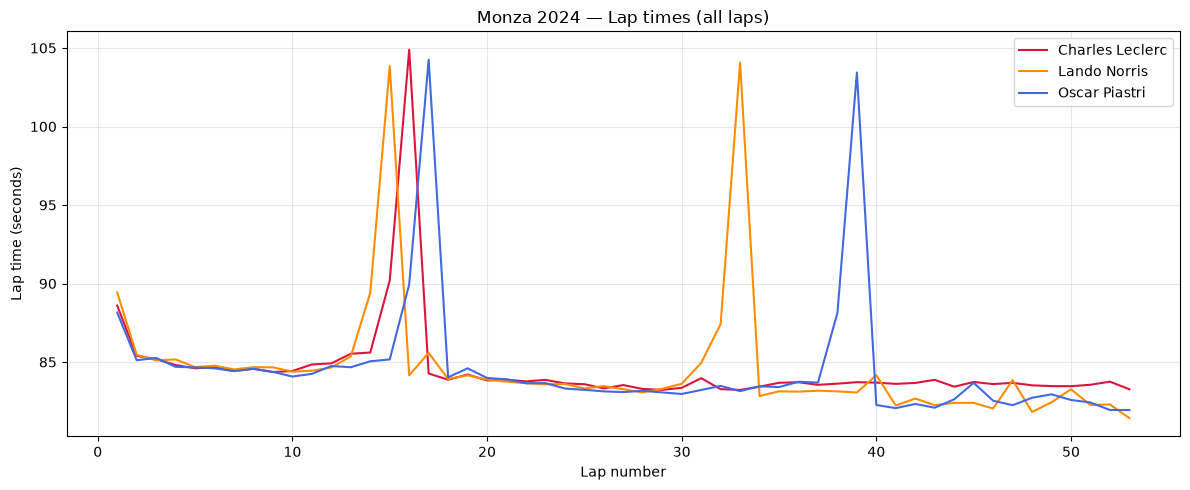

In [7]:
driver_names = {
    16: "Charles Leclerc",
    4: "Lando Norris",
    81: "Oscar Piastri",
}

colors = {
    16: "crimson",
    4: "darkorange",
    81: "royalblue",
}

fig, ax = plt.subplots(figsize=(12, 5))

for number in selected_numbers:
    driver_laps = selected_laps.loc[
        selected_laps["driver_number"] == number
    ].sort_values("lap_number")

    ax.plot(
        driver_laps["lap_number"],
        driver_laps["lap_duration"],
        label=driver_names[number],
        color=colors[number],
        linewidth=1.5,
    )

ax.set_title("Monza 2024 — Lap times (all laps)")
ax.set_xlabel("Lap number")
ax.set_ylabel("Lap time (seconds)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
pit_out_laps = selected_laps.loc[
    selected_laps["is_pit_out_lap"].eq(True),
    ["driver_number", "lap_number", "lap_duration"],
].copy()

pit_out_laps["driver"] = pit_out_laps["driver_number"].map(driver_names)

display(
    pit_out_laps[["driver", "lap_number", "lap_duration"]]
    .sort_values(["driver", "lap_number"])
)

,driver,lap_number,lap_duration
295,Charles Leclerc,16,104.888
277,Lando Norris,15,103.840
618,Lando Norris,33,104.073
312,Oscar Piastri,17,104.250
726,Oscar Piastri,39,103.438


In [9]:
response = requests.get(
    "https://api.openf1.org/v1/stints",
    params={"session_key": session_key},
    timeout=30,
)
response.raise_for_status()

stints = pd.DataFrame(response.json())

selected_stints = stints.loc[
    stints["driver_number"].isin(selected_numbers)
].copy()

selected_stints["driver"] = selected_stints["driver_number"].map(
    driver_names
)

display(
    selected_stints[[
        "driver",
        "stint_number",
        "compound",
        "lap_start",
        "lap_end",
        "tyre_age_at_start",
    ]].sort_values(["driver", "stint_number"])
)

,driver,stint_number,compound,lap_start,lap_end,tyre_age_at_start
12,Charles Leclerc,1,MEDIUM,1,15,0
27,Charles Leclerc,2,HARD,16,53,0
3,Lando Norris,1,MEDIUM,1,14,0
25,Lando Norris,2,HARD,15,32,0
39,Lando Norris,3,HARD,33,53,0
8,Oscar Piastri,1,MEDIUM,1,16,0
30,Oscar Piastri,2,HARD,17,38,0
47,Oscar Piastri,3,HARD,39,53,0


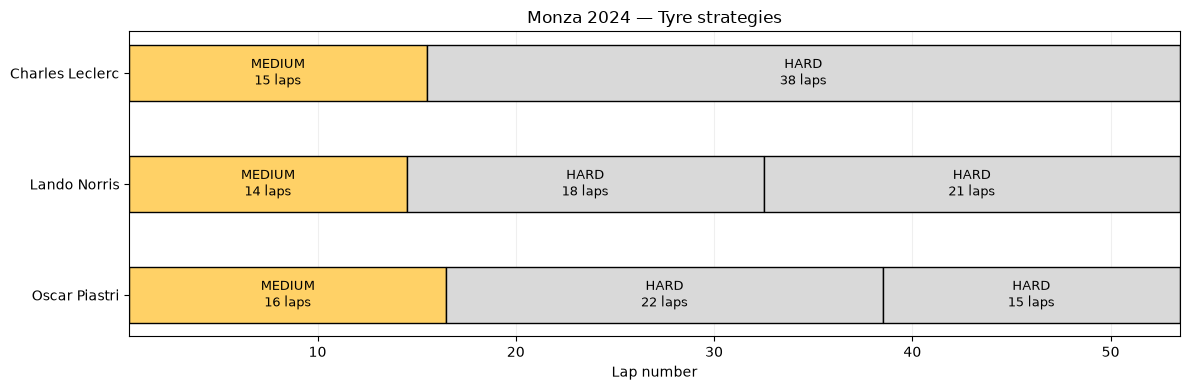

In [10]:
tyre_colors = {
    "SOFT": "#e63946",
    "MEDIUM": "#ffd166",
    "HARD": "#d9d9d9",
}

fig, ax = plt.subplots(figsize=(12, 4))

for row, number in enumerate(selected_numbers):
    driver_stints = selected_stints.loc[
        selected_stints["driver_number"] == number
    ].sort_values("stint_number")

    for _, stint in driver_stints.iterrows():
        start = int(stint["lap_start"])
        end = int(stint["lap_end"])
        length = end - start + 1

        ax.barh(
            row,
            length,
            left=start - 0.5,
            height=0.5,
            color=tyre_colors.get(stint["compound"], "lightblue"),
            edgecolor="black",
        )

        ax.text(
            (start + end) / 2,
            row,
            f"{stint['compound']}\n{length} laps",
            ha="center",
            va="center",
            fontsize=9,
        )

ax.set_yticks(range(len(selected_numbers)))
ax.set_yticklabels([driver_names[n] for n in selected_numbers])
ax.invert_yaxis()
ax.set_xlim(0.5, 53.5)
ax.set_xlabel("Lap number")
ax.set_title("Monza 2024 — Tyre strategies")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

In [11]:
pace_laps = selected_laps.sort_values(
    ["driver_number", "lap_number"]
).copy()

# После сортировки проверяем, является ли следующий круг выездным.
pace_laps["is_pit_in_lap"] = (
    pace_laps.groupby("driver_number")["is_pit_out_lap"]
    .shift(-1)
    .eq(True)
)

exclude = (
    pace_laps["lap_number"].eq(1)
    | pace_laps["is_pit_out_lap"].eq(True)
    | pace_laps["is_pit_in_lap"]
)

pace_laps = pace_laps.loc[~exclude].copy()

counts = (
    pace_laps.groupby("driver_number")
    .size()
    .rename("laps_remaining")
)
display(counts)

driver_number
4     48
16    50
81    48
Name: laps_remaining, dtype: int64

In [12]:
pace_summary = pace_laps.groupby("driver_number").agg(
    laps=("lap_duration", "size"),
    median_seconds=("lap_duration", "median"),
    std_seconds=("lap_duration", "std"),
    fastest_seconds=("lap_duration", "min"),
)

pace_summary["driver"] = pace_summary.index.map(driver_names)

display(
    pace_summary[[
        "driver",
        "laps",
        "median_seconds",
        "std_seconds",
        "fastest_seconds",
    ]].sort_values("median_seconds").round(3)
)

,driver,laps,median_seconds,std_seconds,fastest_seconds
driver_number,,,,,
81,Oscar Piastri,48,83.468,0.951,81.943
4,Lando Norris,48,83.591,1.044,81.432
16,Charles Leclerc,50,83.716,0.629,83.226


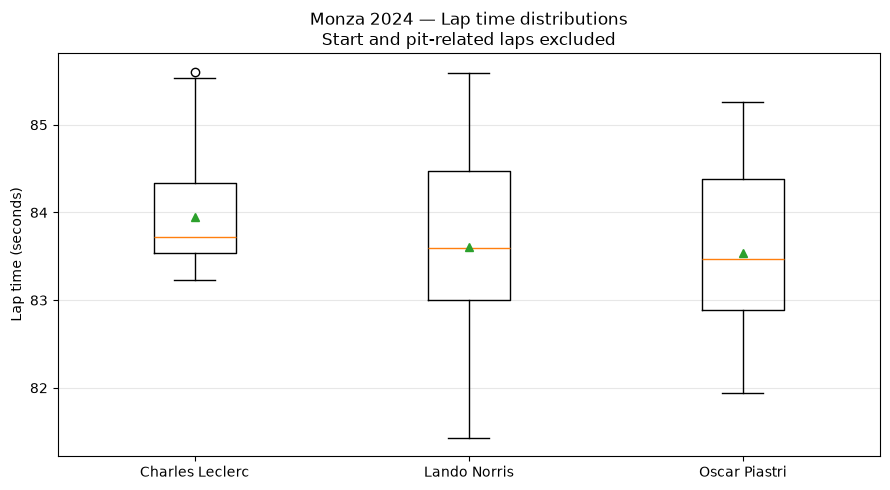

In [13]:
lap_time_groups = [
    pace_laps.loc[
        pace_laps["driver_number"] == number,
        "lap_duration",
    ].to_numpy()
    for number in selected_numbers
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    lap_time_groups,
    tick_labels=[driver_names[n] for n in selected_numbers],
    showmeans=True,
)

ax.set_title("Monza 2024 — Lap time distributions\nStart and pit-related laps excluded")
ax.set_ylabel("Lap time (seconds)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
response = requests.get(
    "https://api.openf1.org/v1/race_control",
    params={"session_key": session_key},
    timeout=30,
)
response.raise_for_status()

race_control = pd.DataFrame(response.json())

relevant = (
    race_control["category"].eq("SafetyCar")
    | race_control["message"].str.contains(
        r"SAFETY CAR|\bVSC\b|RED FLAG",
        case=False,
        na=False,
    )
    | race_control["flag"].eq("RED")
)

events = race_control.loc[
    relevant,
    ["date", "lap_number", "category", "flag", "message"],
].sort_values("date")

print("Найдено сообщений:", len(events))
display(events)

Найдено сообщений: 1


,date,lap_number,category,flag,message
58,2024-09-01T14:18:15+00:00,53,Flag,CHEQUERED,CHEQUERED FLAG


In [15]:
relevant = (
    race_control["category"].eq("SafetyCar")
    | race_control["message"].str.contains(
        r"\b(?:SAFETY CAR|VSC|RED FLAG)\b",
        case=False,
        na=False,
    )
    | race_control["flag"].eq("RED")
)

events = race_control.loc[
    relevant,
    ["date", "lap_number", "category", "flag", "message"],
].sort_values("date")

print("Найдено сообщений:", len(events))
display(events)

Найдено сообщений: 0


,date,lap_number,category,flag,message


In [16]:
from pathlib import Path

data_dir = Path("data/raw")
data_dir.mkdir(parents=True, exist_ok=True)

tables = {
    "drivers": drivers,
    "laps": laps,
    "stints": stints,
    "race_control": race_control,
}

for name, table in tables.items():
    file_path = data_dir / f"monza_2024_{name}.csv"
    table.to_csv(file_path, index=False)
    print("Сохранено:", file_path)

print("Папка данных:", data_dir.resolve())

Сохранено: data\raw\monza_2024_drivers.csv
Сохранено: data\raw\monza_2024_laps.csv
Сохранено: data\raw\monza_2024_stints.csv
Сохранено: data\raw\monza_2024_race_control.csv
Папка данных: C:\Users\Aisha\f1-race-analysis\data\raw
